ML PROJECT: STUDENT PERFORMANCE PREDICTION

Name: Alina Usman
Roll Number: 24F-AI-146

Objective:
To predict students' math scores using Machine Learning.
NumPy and Pandas are used for data analysis, IQR is used
for outlier detection, and two ML models are trained and compared.

**Import libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
from google.colab import files

uploaded = files.upload()

Saving StudentsPerformance.csv to StudentsPerformance.csv


LOAD DATASET

In [4]:
df = pd.read_csv(next(iter(uploaded)))

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [6]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

df.describe()

Shape: (1000, 8)

Columns:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [7]:
scores = df["math score"].to_numpy()

print("Mean:", np.mean(scores))
print("Maximum:", np.max(scores))
print("Minimum:", np.min(scores))
print("Standard Deviation:", np.std(scores))

Mean: 66.089
Maximum: 100
Minimum: 0
Standard Deviation: 15.155496659628149


OUTLIER DETECTION

The Interquartile Range (IQR) method is used to detect
outliers in the math score column.

In [9]:
Q1 = df["math score"].quantile(0.25)
Q3 = df["math score"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["math score"] < lower) | (df["math score"] > upper)]

print("Number of outliers:", len(outliers))

Number of outliers: 8


In [10]:
df_clean = df[
    (df["math score"] >= lower) &
    (df["math score"] <= upper)
].copy()

print("Original rows:", len(df))
print("Rows after removing outliers:", len(df_clean))

Original rows: 1000
Rows after removing outliers: 992


DATA PREPARATION

Categorical features are converted into numerical values
using One-Hot Encoding before training the models.

In [12]:
X = df_clean.drop(columns=["math score"])
y = df_clean["math score"]

categorical = X.select_dtypes(include=["object"]).columns
numeric = X.select_dtypes(exclude=["object"]).columns

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("num", "passthrough", numeric)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

MODEL 1: LINEAR REGRESSION

Linear Regression is used as the first prediction model.

In [13]:
model1 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

model1.fit(X_train, y_train)

pred1 = model1.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))
print("R2 Score:", r2_score(y_test, pred1))

MAE: 4.085098486148221
RMSE: 5.087236199318482
R2 Score: 0.8869117880771317


MODEL 2: RANDOM FOREST REGRESSOR

Random Forest is used as the second model to compare
its performance with Linear Regression.

In [14]:
model2 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

model2.fit(X_train, y_train)

pred2 = model2.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))
print("R2 Score:", r2_score(y_test, pred2))

MAE: 4.427289782244556
RMSE: 5.548007717223733
R2 Score: 0.86549833957594


COMPARE BOTH MODELS

In [15]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, pred1),
        mean_absolute_error(y_test, pred2)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred1)),
        np.sqrt(mean_squared_error(y_test, pred2))
    ],
    "R2 Score": [
        r2_score(y_test, pred1),
        r2_score(y_test, pred2)
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.085098,5.087236,0.886912
1,Random Forest,4.427290,5.548008,0.865498


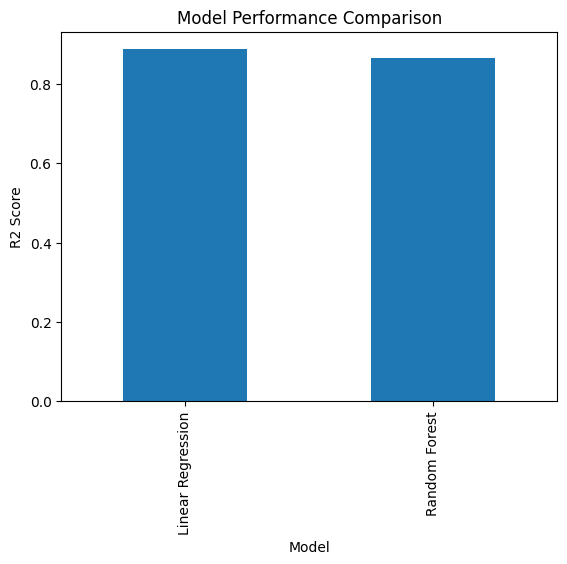

In [16]:
results.plot(x="Model", y="R2 Score", kind="bar", legend=False)

plt.title("Model Performance Comparison")
plt.ylabel("R2 Score")
plt.show()

CONCLUSION

The student performance dataset was analyzed using NumPy and Pandas.
Outliers were detected and removed using the IQR technique.

Two Machine Learning models, Linear Regression and Random Forest,
were trained to predict math scores. Their performance was compared
using MAE, RMSE and R2 Score.